# Símbolos manuscritos → LaTeX: entrenamiento y resultados

**PC2 de Computación Gráfica — UNI.** Se reconocen seis símbolos aislados: α, ξ, ∞, ≡, ∂ y ∈. Se entrena la CNN de `src/model.py`, se evalúan imágenes reservadas de HASY o personas distintas en capturas propias y se guardan métricas y un modelo reutilizable por la aplicación.

Esta copia incluye un **experimento de referencia con HASYv2 público**. Sus cifras no demuestran el desempeño con mouse ni acreditan recolección propia. La consigna solicita 500–1000 ejemplos por categoría; no indica expresamente si admite sustituir la recolección por un dataset público.

Fuentes: [HASY](https://github.com/MartinThoma/HASY), [dataset y checksum](https://doi.org/10.5281/zenodo.259444), [artículo de Martin Thoma](https://arxiv.org/abs/1701.08380).

## Ejecutar en Ubuntu con VS Code

Desde la raíz del proyecto, activa `.venv` e instala `requirements.txt`, `requirements-cpu.txt`, `requirements-ml.txt` y `requirements-notebook.txt`. Abre este archivo en VS Code, elige **Select Kernel → Python Environments → .venv** y ejecuta las celdas en orden. También se puede ejecutar con `python -m scripts.run_notebook`.

La descarga y la instalación iniciales requieren internet. El entrenamiento y la aplicación funcionan después en CPU y localmente.


In [1]:
from pathlib import Path
import sys
import json
import platform

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/symbols.json").is_file() and (p / "src/model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abre el notebook desde la carpeta del repositorio en VS Code.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import torch
from IPython.display import display, Markdown, Image as NotebookImage
from src.hasy_import import download_hasy, prepare_hasy, HASY_MD5
from src.training_data import load_dataset, split_dataset
from src.training import train_model

print("Python:", platform.python_version(), "NumPy:", np.__version__, "PyTorch:", torch.__version__)


Python: 3.12.14 NumPy: 2.2.6 PyTorch: 2.7.1+cpu


## 1. Configuración del experimento

Deja `SOURCE = "hasy"` para reproducir el experimento público. Para tus capturas, cambia a `SOURCE = "own"`, prepara antes los datos desde Flask y conserva los códigos reales de cada participante. Los códigos `DEMO...` se excluyen.

La semilla fija la selección y las particiones. Para comparar arquitecturas, conserva las personas de prueba, incluso cuando amplíes la colección. `PILOT_OWN = True` permite un ensayo con menos de la meta; no convierte sus métricas en resultados definitivos.


In [2]:
SOURCE = "hasy"       # "hasy" o "own"
PER_CLASS = 800
SEED = 42
EPOCHS = 25
PILOT_OWN = True
EXPERIMENT = "hasy-notebook" if SOURCE == "hasy" else "own-notebook"
OUTPUT = ROOT / "models" / EXPERIMENT

if SOURCE not in ("hasy", "own"):
    raise ValueError("SOURCE debe ser hasy u own.")
DATA = ROOT / "data" / "hasy" / "processed" if SOURCE == "hasy" else ROOT / "data" / "processed"
print("Origen:", SOURCE, "Experimento:", EXPERIMENT)


Origen: hasy Experimento: hasy-notebook


## 2. Preparar y revisar los datos

HASYv2 proporciona `path, symbol_id, latex, user_id`. La importación valida los seis IDs contra los comandos, descarta dibujos vacíos, IDs de origen inválidos y PNG idénticos, y selecciona 800 ejemplos únicos por clase con semilla 42. Se aplica el mismo preprocesamiento que al lienzo: fondo cero, tinta alta, recorte y centrado con margen.

El dataset público se guarda en `data/hasy/`; las capturas de la aplicación permanecen en `data/raw/`. No se mezclan. Se conservan los IDs de origen con el prefijo `HASY_`, pero no se consideran personas: el ID `16925` agrupa contribuciones de Detexify y los demás IDs tampoco son identidades fiables. Véase la sección III del artículo original.


In [3]:
if SOURCE == "hasy":
    if not DATA.is_dir():
        archive = download_hasy(ROOT / "data" / "external" / "HASYv2.tar.bz2")
        imported = prepare_hasy(archive, ROOT / "data" / "hasy", per_class=PER_CLASS, seed=SEED)
    else:
        imported = json.loads((DATA / "metadata.json").read_text(encoding="utf-8"))
        if (imported.get("source_type") != "hasyv2" or imported.get("per_class") != PER_CLASS
                or imported.get("selection_seed") != SEED or imported.get("archive_md5") != HASY_MD5):
            raise ValueError("El subconjunto existente no corresponde a esta configuración. Conserva los datos y usa otro directorio.")

dataset = load_dataset(DATA)
print("Origen real:", dataset.source_description)
print("X:", dataset.X.shape, dataset.X.dtype, "y:", dataset.y.shape)
print("IDs de origen" if SOURCE == "hasy" else "Participantes", len(set(dataset.participants)), "Demos excluidas:", dataset.excluded_demo)
print("Huella SHA-256:", dataset.fingerprint)
counts = np.bincount(dataset.y, minlength=6)
table = "| Clase | Símbolo | LaTeX | Muestras |\n|---|:---:|---|---:|\n"
for symbol, count in zip(dataset.catalog["symbols"], counts):
    table += f"| {symbol['id']} | {symbol['unicode']} | {symbol['latex']} | {count} |\n"
display(Markdown(table))


Origen real: subconjunto del dataset publico HASYv2
X: (4800, 32, 32, 1) float32 y: (4800,)
IDs de origen 54 Demos excluidas: 0
Huella SHA-256: 24b4ee2ed0dc263ecca9de022678bb003d1c372558125ed49742a904b70c9a39


| Clase | Símbolo | LaTeX | Muestras |
|---|:---:|---|---:|
| alpha | α | \alpha | 800 |
| xi | ξ | \xi | 800 |
| infty | ∞ | \infty | 800 |
| equiv | ≡ | \equiv | 800 |
| partial | ∂ | \partial | 800 |
| in | ∈ | \in | 800 |


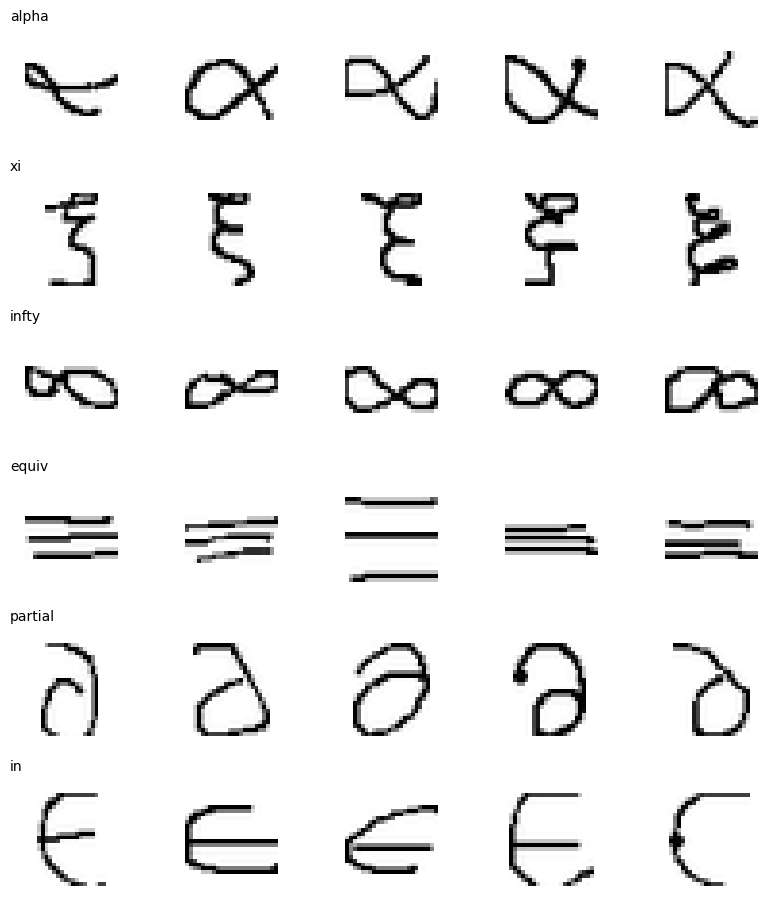

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 5, figsize=(8, 9), layout="constrained")
for class_index, symbol in enumerate(dataset.catalog["symbols"]):
    indices = np.flatnonzero(dataset.y == class_index)[:5]
    for column, ax in enumerate(axes[class_index]):
        ax.axis("off")
        if column < len(indices):
            ax.imshow(1 - dataset.X[indices[column], ..., 0], cmap="gray", vmin=0, vmax=1)
        if column == 0:
            ax.set_title(symbol["id"], loc="left", fontsize=10)
plt.show()


## 3. Separación según el origen

Para HASY se separan **imágenes estratificadas por clase**, 70 % para entrenamiento, 15 % para validación y 15 % para prueba. Sus `user_id` no permiten evaluar autores nuevos: el ID `16925` reúne trazos de numerosas personas y los IDs restantes tampoco garantizan una identidad estable, según la sección III del artículo original.

Para capturas propias se asignan participantes completos y se exige que las seis clases estén presentes en cada partición. Ningún dibujo de una persona de prueba se utiliza para entrenar o seleccionar la época.

Se verifica que cada imagen pertenezca a una única partición. **Este protocolo es propio del proyecto** y no reproduce el benchmark oficial de diez folds; las cifras no se comparan directamente con las del artículo.


In [5]:
partitions = split_dataset(dataset, seed=SEED)
groups = {name: set(dataset.participants[indices].tolist()) for name, indices in partitions.items()}
if SOURCE == "own":
    assert not groups["train"] & groups["validation"]
    assert not groups["train"] & groups["test"]
    assert not groups["validation"] & groups["test"]

for name, indices in partitions.items():
    print(name, "muestras:", len(indices), "IDs de origen" if SOURCE == "hasy" else "participantes", len(groups[name]),
          "conteos:", np.bincount(dataset.y[indices], minlength=6).tolist())
assert sorted(np.concatenate(list(partitions.values())).tolist()) == list(range(len(dataset.y)))


train muestras: 3360 IDs de origen 43 conteos: [560, 560, 560, 560, 560, 560]
validation muestras: 720 IDs de origen 17 conteos: [120, 120, 120, 120, 120, 120]
test muestras: 720 IDs de origen 16 conteos: [120, 120, 120, 120, 120, 120]


## 4. Entrenar la CNN

Dos convoluciones (16 y 32 filtros), ReLU, pooling, una capa de 64 unidades y dropout producen seis logits. Adam minimiza entropía cruzada. Se conserva la época con menor pérdida de validación; se detiene tras cinco épocas sin mejora y se evalúa prueba al terminar. Esta primera versión no usa aumentos de datos.

Si el directorio del experimento ya existe, se leen sus resultados solo si coinciden el dataset, la semilla y el número de épocas solicitado. Para entrenar otro experimento cambia `EXPERIMENT`: no se sobrescribe el anterior.


In [6]:
if OUTPUT.exists():
    info = json.loads((OUTPUT / "model_info.json").read_text(encoding="utf-8"))
    if (info["dataset_sha256"] != dataset.fingerprint or info["seed"] != SEED
            or info.get("epochs_requested") != EPOCHS):
        raise ValueError("El experimento existente usa otra configuración. Elige otro EXPERIMENT.")
    metrics = json.loads((OUTPUT / "metrics.json").read_text(encoding="utf-8"))
    print("Resultados guardados del mismo experimento; no se ha vuelto a entrenar.")
    print("Historial real del entrenamiento original (history.json):")
    for row in json.loads((OUTPUT / "history.json").read_text(encoding="utf-8")):
        print(f"Época {row['epoch']:02d}: pérdida={row['train_loss']:.4f}; "
              f"validación={row['validation_loss']:.4f}; acc_val={row['validation_accuracy']:.3f}")
else:
    info, metrics = train_model(dataset, OUTPUT, epochs=EPOCHS, seed=SEED,
                                pilot=PILOT_OWN if SOURCE == "own" else True, threads=4)

print("Mejor época:", info["best_epoch"], "Épocas ejecutadas:", info["epochs_run"])
print("Tipo:", info["purpose"], "Origen:", info["source_type"])


Resultados guardados del mismo experimento; no se ha vuelto a entrenar.
Historial real del entrenamiento original (history.json):
Época 01: pérdida=0.7458; validación=0.2281; acc_val=0.932
Época 02: pérdida=0.2015; validación=0.1321; acc_val=0.965
Época 03: pérdida=0.1317; validación=0.1056; acc_val=0.971
Época 04: pérdida=0.1027; validación=0.0988; acc_val=0.974
Época 05: pérdida=0.0877; validación=0.0831; acc_val=0.978
Época 06: pérdida=0.0688; validación=0.0684; acc_val=0.979
Época 07: pérdida=0.0625; validación=0.0612; acc_val=0.983
Época 08: pérdida=0.0468; validación=0.0654; acc_val=0.982
Época 09: pérdida=0.0394; validación=0.0753; acc_val=0.976
Época 10: pérdida=0.0340; validación=0.0676; acc_val=0.982
Época 11: pérdida=0.0307; validación=0.0676; acc_val=0.985
Época 12: pérdida=0.0222; validación=0.0722; acc_val=0.986
Mejor época: 7 Épocas ejecutadas: 12
Tipo: external_baseline Origen: hasyv2


## 5. Resultados y errores

Top-1 exige que la primera propuesta sea correcta. Top-3 permite acertar con alguna de tres propuestas distintas. Con seis clases, la referencia aleatoria uniforme es 16.7 % y 50 %, respectivamente. F1 macro da el mismo peso a cada clase.

La matriz usa **filas reales y columnas predichas**. Una puntuación softmax no es una probabilidad calibrada de que la respuesta sea correcta. Estas cifras evalúan solo los seis símbolos y las imágenes reservadas del conjunto elegido. Solo la evaluación de capturas propias con códigos estables permite reservar personas.


In [7]:
print("Muestras de prueba:", metrics["n_samples"])
print(f"Accuracy top-1: {metrics['top_1_accuracy']:.4f}")
print(f"Accuracy top-3: {metrics['top_3_accuracy']:.4f}")
print(f"F1 macro: {metrics['macro_f1']:.4f}")
print("Referencia aleatoria:", metrics["uniform_random_baseline"])

table = "| Clase | Precisión | Recall | F1 | Soporte |\n|---|---:|---:|---:|---:|\n"
for row in metrics["per_class"]:
    table += f"| {row['id']} | {row['precision']:.3f} | {row['recall']:.3f} | {row['f1']:.3f} | {row['support']} |\n"
display(Markdown(table))
print("Orden de clases:", metrics["class_order"])
print("Matriz de confusión:\n", np.asarray(metrics["confusion_matrix"]))


Muestras de prueba: 720
Accuracy top-1: 0.9861
Accuracy top-3: 0.9986
F1 macro: 0.9861
Referencia aleatoria: {'top_1_accuracy': 0.16666666666666666, 'top_3_accuracy': 0.5}
Orden de clases: ['alpha', 'xi', 'infty', 'equiv', 'partial', 'in']
Matriz de confusión:
 [[117   0   2   0   0   1]
 [  0 117   0   0   0   3]
 [  0   0 120   0   0   0]
 [  0   0   0 120   0   0]
 [  2   0   0   0 118   0]
 [  0   2   0   0   0 118]]


| Clase | Precisión | Recall | F1 | Soporte |
|---|---:|---:|---:|---:|
| alpha | 0.983 | 0.975 | 0.979 | 120 |
| xi | 0.983 | 0.975 | 0.979 | 120 |
| infty | 0.984 | 1.000 | 0.992 | 120 |
| equiv | 1.000 | 1.000 | 1.000 | 120 |
| partial | 1.000 | 0.983 | 0.992 | 120 |
| in | 0.967 | 0.983 | 0.975 | 120 |


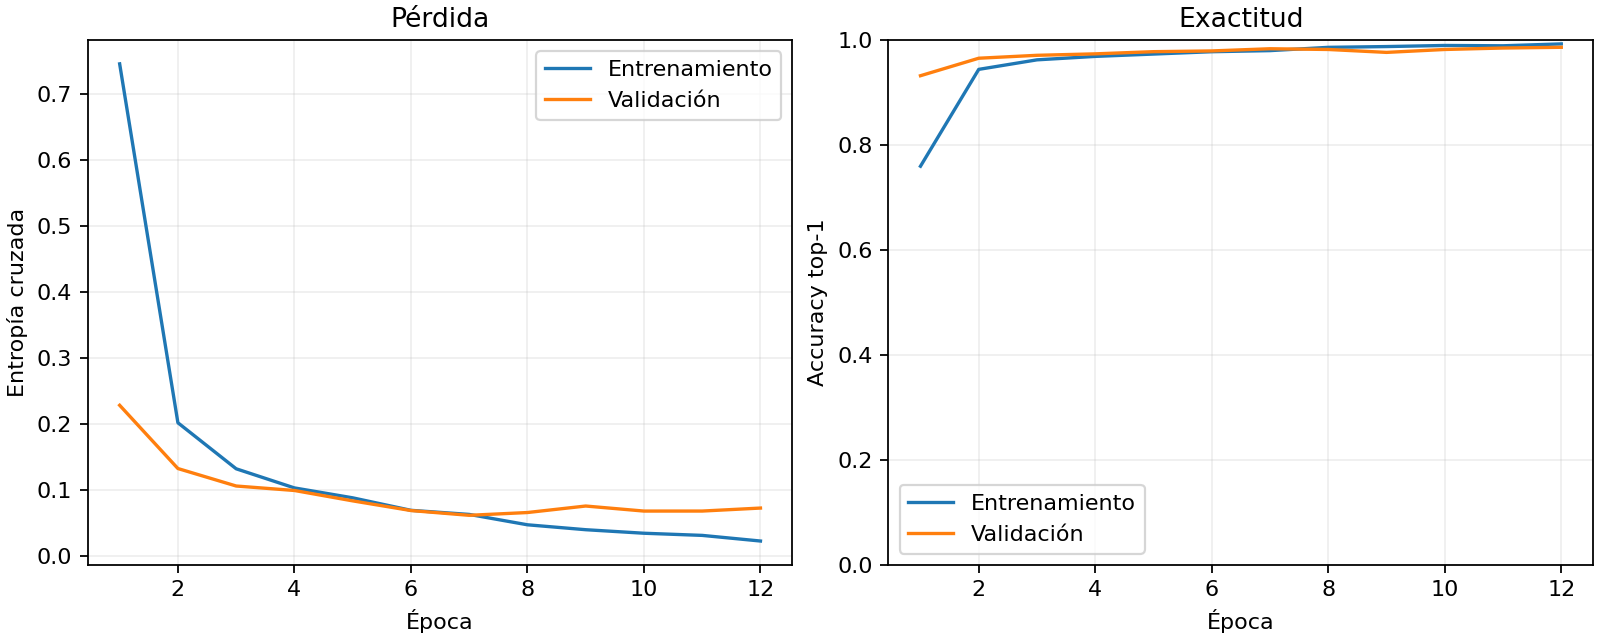

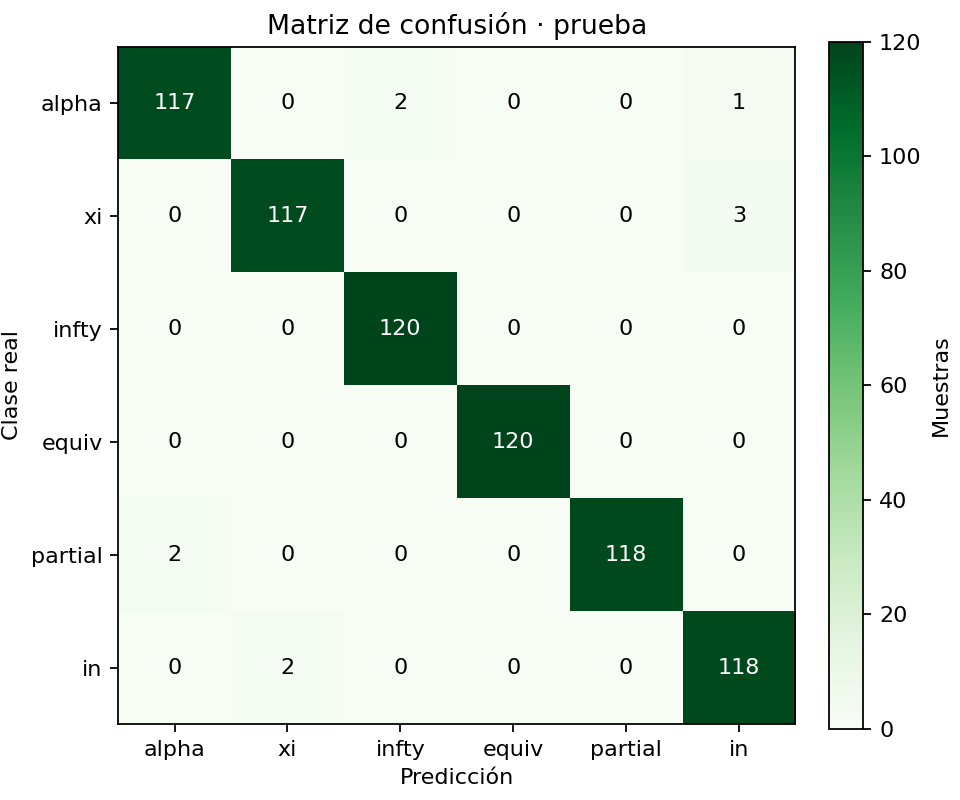

In [8]:
display(NotebookImage(filename=str(OUTPUT / "learning_curves.png")))
display(NotebookImage(filename=str(OUTPUT / "confusion_matrix.png")))


## 6. Comprobar la integración con Flask

La siguiente celda toma un PNG real de la partición de prueba y lo envía a la misma ruta `/predict` que utiliza la página. Comprueba que los comandos estén en el catálogo y que una consulta no se añada al dataset. No sustituye la prueba manual con mouse ni la revisión humana de etiquetas.


In [9]:
from main import create_app
import base64

test_index = int(partitions["test"][0])
record = dataset.records[test_index]
raw_directory = DATA.parent / "raw"
png = (raw_directory / record["path"]).read_bytes()
client = create_app(ROOT / "reports" / "notebook-query", OUTPUT).test_client()
before = client.get("/api/counts").json["counts"]
response = client.post("/predict", json={"image": "data:image/png;base64," + base64.b64encode(png).decode("ascii")})
assert response.status_code == 200, response.json
assert len(response.json["candidates"]) == 3
assert client.get("/api/counts").json["counts"] == before
assert {c["latex"] for c in response.json["candidates"]} <= {s["latex"] for s in dataset.catalog["symbols"]}
print("Clase real:", record["class_id"])
for candidate in response.json["candidates"]:
    print(candidate["unicode"], candidate["name"], candidate["latex"])
print("Modelo compatible e integración verificada.")


Clase real: alpha
α Alfa minúscula \alpha
≡ Equivalencia \equiv
∈ Pertenencia \in
Modelo compatible e integración verificada.


## Lectura del experimento de referencia

En la ejecución incluida, la primera propuesta acertó 710 de 720 imágenes (98.61 %) y alguna de las tres acertó 719 (99.86 %). Se recuperaron nueve errores al mostrar alternativas. La confusión más frecuente fue `xi` → `in`, con tres casos. La época 7 tuvo la menor pérdida de validación; se detuvo el entrenamiento tras la época 12. El conjunto de prueba no se utilizó para elegir esa época.

Estos resultados justifican probar las tres sugerencias en la interfaz, pero no demuestran desempeño con dibujantes nuevos: HASY no identifica personas fiables. Falta una evaluación independiente con capturas nuevas y etiquetas revisadas por el equipo. Si cambias de experimento, actualiza este análisis a partir de sus salidas reales.

## Preguntas que deben completar los integrantes

- ¿Qué clases se confunden más según la matriz y por qué sus trazos pueden parecerse?
- ¿Cuánto aporta top-3 respecto a top-1 y a su referencia aleatoria del 50 %?
- ¿Cuántas muestras hay realmente en prueba? ¿El origen permite conocer y reservar personas?
- ¿Qué cambia al dibujar con mouse en lugar de usar los PNG de HASY?
- ¿Qué ejemplos son incorrectos o ambiguos y cómo los revisaron?
- Si usan datos públicos, ¿qué parte corresponde a datos públicos y qué parte recolectó el equipo?

Para activar este experimento en la aplicación, ejecuta desde la raíz:

```bash
LATEX_MODEL_DIR=models/hasy-notebook python main.py
```

Para una entrega basada en capturas propias, cambia el origen a `own`, completa la recolección y usa `PILOT_OWN = False`. Guarda el notebook ejecutado y presenta sus resultados reales. Todos los integrantes deben exponer.
